In [1]:
from matplotlib.gridspec import GridSpec
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.patches import Patch
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib
from itertools import product, combinations
import sys 
sys.path.extend(['/Users/amonast/Documents/GitHub/zlab_miniscope'])
from load_traces import load_aligned_act, build_intervals, get_tuned_df, get_co_tuned_cells
from scipy.ndimage import gaussian_filter1d


# Set up

In [2]:
color_map = {
    'Aggressive':        "#ec2024",
    'Pro-Social':        "#4e69b0",
    'Social Avoidance':  "#c091c1",
    'Other':            "#696868",
    'Mixed':                "#4CAF50"}
traces_dir    = '/Users/amonast/Desktop/miniscope/Traces'
behavior_csv  = '/Users/amonast/Desktop/miniscope/data/tuning/intervals_allmice.csv'
data_info_csv = '/Users/amonast/Desktop/miniscope/dbnst_data_info.csv'
data_dir      = '/Users/amonast/Desktop/miniscope/data'

animals       = pd.read_csv(data_info_csv)['Mouse'].unique()
tuned_ids,tuned_df = get_tuned_df(animals, data_dir)
tuned_ids

,animal,session,behavior_type,tuned_cells
0,C0F2C,R2,Aggressive,[39]
1,C0F2C,R2,Other,[8]
2,C0F2C,R2,Pro-Social,"[0, 2, 7, 8, 9, 11, 14, 16, 18, 21, 23, 25, 27..."
3,C0F2C,R2,Social Avoidance,"[29, 48, 53, 59, 60, 64]"
4,C1F2,R1,Aggressive,"[0, 13, 19, 33, 59]"
...,...,...,...,...
70,C3M4,R1,Social Avoidance,"[16, 17]"
71,C3M4,R2,Aggressive,"[27, 42, 49, 51]"
72,C3M4,R2,Other,"[3, 4, 28, 57, 58]"
73,C3M4,R2,Pro-Social,"[0, 5, 6, 7, 8, 11, 14, 15, 17, 18, 20, 26, 27..."


In [3]:
# Cells significantly (p<=0.05) and positively (z>0) tuned to BOTH Aggressive and Pro-Social
co_tuned = get_co_tuned_cells(tuned_df, 'Aggressive', 'Pro-Social', exclude_animals=['C2M4', 'C2F1'])

co_tuned_cell_ids = {
    f"{row['animal']}_{row['session']}_{c}"
    for _, row in co_tuned.iterrows()
    for c in row['co_tuned_cells']
}

co_tuned

,animal,session,co_tuned_cells
0,C0F2C,R2,[]
1,C1F2,R1,[19]
2,C1F2,R2,"[7, 8, 36]"
3,C1M2,R2,[]
4,C3M2,R1,[]
5,C3M2,R2,"[21, 43, 47]"
6,C3M3,R1,[19]
7,C3M3,R2,"[15, 19]"
8,C3M4,R1,[]
9,C3M4,R2,"[27, 42, 49]"


# Functions

In [4]:
def n_positive(row):
    try:
        z_row = tuned_df.loc[(row["animal"], row["session"], row["behavior_type"], "zscore")]
    except KeyError:
        return 0
    if not row["tuned_cells"]:
        return 0
    return sum(float(z_row[c]) > 2 for c in row["tuned_cells"])

def n_negative(row):
    try:
        z_row = tuned_df.loc[(row["animal"], row["session"], row["behavior_type"], "zscore")]
    except KeyError:
        return 0
    if not row["tuned_cells"]:
        return 0
    return sum(float(z_row[c]) < 0 for c in row["tuned_cells"])

def get_mixed_cell_ids(tuned_df, btypes):
    """Cells co-tuned (p<=0.05, z>0) to any pair of behaviors in btypes."""
    mixed = set()
    for bt_a, bt_b in combinations(btypes, 2):
        exclude = ['C2M4', 'C2F1'] if 'Aggressive' in (bt_a, bt_b) else None
        co = get_co_tuned_cells(tuned_df, bt_a, bt_b, exclude_animals=exclude)
        for _, row in co.iterrows():
            for c in row['co_tuned_cells']:
                mixed.add(f"{row['animal']}_{row['session']}_{c}")
    return mixed

def proportion_counts(tuned_ids, animal_set, btypes, tuned_df):
    sub = tuned_ids[tuned_ids["animal"].isin(animal_set) & tuned_ids["behavior_type"].isin(btypes)]

    mixed_cell_ids = get_mixed_cell_ids(tuned_df, btypes)
    zscores_wide = tuned_df.xs('zscore', level='metric')

    category_counts = {bt: 0 for bt in btypes}
    category_counts["Mixed"] = 0
    n_unique_cells = 0  # <-- add
    for (ani, ses), grp in sub.groupby(["animal", "session"]):
        cell_to_btypes = {}
        for _, row in grp.iterrows():
            for cell in row["tuned_cells"]:
                cell_to_btypes.setdefault(cell, set()).add(row["behavior_type"])
        n_unique_cells += len(cell_to_btypes)  # <-- add

        for cell, cell_btypes in cell_to_btypes.items():
            cell_id = f"{ani}_{ses}_{cell}"
            if cell_id in mixed_cell_ids:
                category_counts["Mixed"] += 1
            elif len(cell_btypes) == 1:
                category_counts[next(iter(cell_btypes))] += 1
            else:
                # tuned (p<=0.05) to multiple categories but not co-tuned (positive) to any pair —
                # assign to whichever has the larger z-score
                best_bt = max(
                    cell_btypes,
                    key=lambda bt: float(zscores_wide.loc[(ani, ses, bt), cell])
                    if (ani, ses, bt) in zscores_wide.index else -np.inf)
                category_counts[best_bt] += 1
    assert sum(category_counts.values()) == n_unique_cells, (
        f"double-counting: {sum(category_counts.values())} category assignments "
        f"vs {n_unique_cells} unique cells")  # <-- add
    
    counts = pd.Series(category_counts).reindex(btypes + ["Mixed"], fill_value=0)
    counts = counts[counts > 0]
    return counts / counts.sum()


# Proportions of Tuned Cells

In [5]:
# count tuned cells 
tuned_ids["n_tuned"] = tuned_ids["tuned_cells"].apply(len)

# Which animals displayed aggression (any session) 
agg_animals = set(tuned_ids.loc[(tuned_ids["behavior_type"] == "Aggressive") 
                       & (tuned_ids["n_tuned"] > 0), "animal"])
non_agg_animals = set(tuned_ids["animal"]) - agg_animals
print(f'Aggressive animals:{agg_animals}')
print(f'Not-aggressive animals:{non_agg_animals}')

# - negative and positive modulated cells - 
tuned_ids["n_negative"] = tuned_ids.apply(n_negative, axis=1)
tuned_ids["n_positive"] = tuned_ids.apply(n_positive, axis=1)

social_btypes = ["Pro-Social", "Social Avoidance",'Other']
all_btypes    = ["Pro-Social", "Social Avoidance", "Aggressive","Other"]

props_non_agg = proportion_counts(tuned_ids,non_agg_animals, social_btypes, tuned_df)
props_agg     = proportion_counts(tuned_ids,agg_animals,     all_btypes, tuned_df)

Aggressive animals:{'C3M3', 'C3M4', 'C3M2', 'C0F2C', 'C1F2'}
Not-aggressive animals:{'C2F1', 'C2M4', 'C3F3', 'C1M1', 'C1M2', 'C3F4'}


In [6]:
props_non_agg

Pro-Social          0.629808
Social Avoidance    0.235577
Other               0.125000
Mixed               0.009615
dtype: float64

In [7]:
def excit_inhib_proportion(tuned_ids, animal_set, btype, btypes, tuned_df):
    """Fraction of cells bucketed into `btype` (or "Mixed") that are excited (z>0) vs inhibited (z<0).

    Cells significant (p<=0.05) in more than one of `btypes` are bucketed as
    "Mixed" first, before any single-category assignment — mirrors the
    bucketing in proportion_counts. For a cell significant in more than one
    category (i.e. a Mixed cell), excited/inhibited is decided by whichever
    of its significant categories has the larger |z|.
    """
    sub = tuned_ids[tuned_ids["animal"].isin(animal_set) & tuned_ids["behavior_type"].isin(btypes)]
    zscores_wide = tuned_df.xs('zscore', level='metric')

    n_excited = 0
    n_inhibited = 0
    n_unique_cells = 0

    for (ani, ses), grp in sub.groupby(["animal", "session"]):
        cell_to_btypes = {}
        for _, row in grp.iterrows():
            for cell in row["tuned_cells"]:
                cell_to_btypes.setdefault(cell, set()).add(row["behavior_type"])

        for cell, cell_btypes in cell_to_btypes.items():
            bucket = "Mixed" if len(cell_btypes) > 1 else next(iter(cell_btypes))
            if bucket != btype:
                continue

            zs = {bt: float(zscores_wide.loc[(ani, ses, bt), cell])
                  for bt in cell_btypes if (ani, ses, bt) in zscores_wide.index}
            if not zs:
                continue

            n_unique_cells += 1
            best_bt = max(zs, key=lambda bt: abs(zs[bt]))
            if zs[best_bt] > 2:
                n_excited += 1
            else:
                n_inhibited += 1

    assert n_excited + n_inhibited == n_unique_cells, (
        f"double-counting: {n_excited + n_inhibited} exc/inh assignments "
        f"vs {n_unique_cells} unique cells in bucket {btype!r}")

    total = n_excited + n_inhibited
    if total == 0:
        return 0.0, 0.0
    return n_excited / total, n_inhibited / total

def nested_pie(tuned_ids,animal_set, btypes, tuned_df, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(4, 4), dpi=150)

    exc_colors = {
        'Pro-Social':       "#2F50F5",
        'Social Avoidance': "#823EC6",
        'Aggressive':       "#EE3C3C",
        'Mixed':            "#4CAF50",
        'Other':"#777777",}
    inh_colors = {
        'Pro-Social':       "#528DF4",
        'Social Avoidance': "#A788C4",
        'Aggressive':       "#E7B8B8",
        'Mixed':            "#A5D6A7",
        'Other':            "#979797",}

    props = proportion_counts(tuned_ids, animal_set, btypes, tuned_df)

    outer_vals, outer_colors = [], []
    for bt in props.index:
        p = props[bt]
        if bt == "Mixed" or p == 0:
            outer_vals.append(p)
            outer_colors.append(exc_colors[bt])
        else:
            exc, inh = excit_inhib_proportion(tuned_ids, animal_set, bt, btypes, tuned_df)
            outer_vals += [p * exc, p * inh]
            outer_colors += [exc_colors[bt], inh_colors[bt]]

    inner_colors = [color_map.get(bt) for bt in props.index]

    ax.pie(outer_vals, radius=1.0, colors=outer_colors,
           wedgeprops=dict(width=0.1, edgecolor='white', linewidth=0.5))
    ax.pie(props.values, radius=0.9, colors=inner_colors,
           wedgeprops=dict(edgecolor='white', linewidth=0.5),
           autopct='%1.0f%%', pctdistance=0.75,
           textprops=dict(fontsize=6, ha='center'))
    return ax


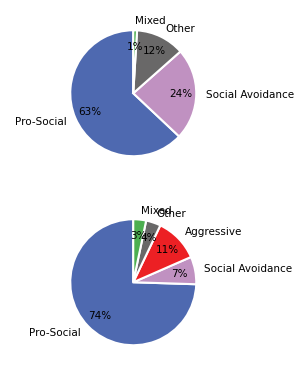

In [8]:
fig, (ax1, ax2) = plt.subplots(2,1, figsize=(1.8,3),dpi=150)
for ax, props, title in [(ax1, props_non_agg, "Non-aggressive mice"),
                         (ax2, props_agg,     "Aggressive mice"),]:
    colors = [color_map.get(b) for b in props.index]
    ax.pie(props.values,
    labels=props.index,
    colors=colors,
    autopct='%1.0f%%',
    pctdistance=0.75,      # pull % labels inward, toward center
    labeldistance=1.15,    # push category labels further out
    textprops=dict(fontsize=5),
    startangle=90,
    wedgeprops=dict(linewidth=1, edgecolor='white'))
    #ax.set_title(title, fontsize=7)
plt.savefig('/Users/amonast/Desktop/miniscope/figures/tuning_pie_chart.svg',transparent=True)

In [9]:
import matplotlib
matplotlib.style.use('paper_style.mplstyle')
exc_colors = {
        'Pro-Social':       "#2F50F5",
        'Social Avoidance': "#823EC6",
        'Aggressive':       "#EE3C3C",
        'Mixed':            "#4CAF50",
        'Other':            "#777777",}
    
inh_colors = {
        'Pro-Social':       "#528DF4",
        'Social Avoidance': "#A788C4",
        'Aggressive':       "#E7B8B8",
        'Mixed':            "#A5D6A7",
        'Other':            "#979797",
    }


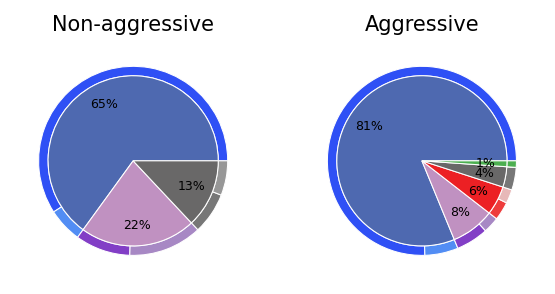

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(4,2), dpi=150)
r1 = tuned_ids.loc[tuned_ids['session']=='R1']
nested_pie(r1,non_agg_animals, social_btypes, tuned_df, ax=ax1)
nested_pie(r1,agg_animals, all_btypes, tuned_df, ax=ax2)
ax1.set_title("Non-aggressive"); ax2.set_title("Aggressive")

legend_handles = [plt.matplotlib.patches.Patch(color=color_map.get(bt), label=bt) 
                  for bt in props.index]
# ax2.legend(handles=legend_handles, loc='lower center',
#           bbox_to_anchor=(0.5, -0.15), fontsize=7, frameon=False, ncol=2)

btypes_all = ["Pro-Social", "Social Avoidance", "Aggressive"]

handles = (
    [Patch(color=exc_colors[bt], label='Excited')   for bt in btypes_all] +
    [Patch(color=inh_colors[bt], label='Inhibited') for bt in btypes_all]
)

# ax1.legend(handles=handles, ncol=2,
#            loc='lower center', bbox_to_anchor=(0.5, -0.25),
#            fontsize=6, frameon=False, handlelength=1, handleheight=1)

plt.tight_layout()
plt.savefig('/Users/amonast/Desktop/miniscope/figures/piecharts_nested_alltuned_r1.svg',transparent=True)

R2

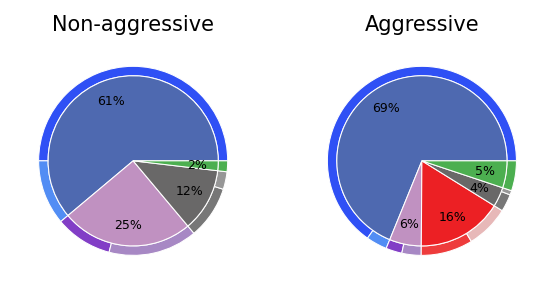

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(4,2), dpi=150)
r2 = tuned_ids.loc[tuned_ids['session']=='R2']
nested_pie(r2,non_agg_animals, social_btypes, tuned_df, ax=ax1)
nested_pie(r2,agg_animals, all_btypes, tuned_df, ax=ax2)
ax1.set_title("Non-aggressive"); ax2.set_title("Aggressive")

legend_handles = [plt.matplotlib.patches.Patch(color=color_map.get(bt), label=bt) 
                  for bt in props.index]
# ax2.legend(handles=legend_handles, loc='lower center',
#           bbox_to_anchor=(0.5, -0.15), fontsize=7, frameon=False, ncol=2)

btypes_all = ["Pro-Social", "Social Avoidance", "Aggressive"]

handles = (
    [Patch(color=exc_colors[bt], label='Excited')   for bt in btypes_all] +
    [Patch(color=inh_colors[bt], label='Inhibited') for bt in btypes_all]
)

# ax1.legend(handles=handles, ncol=2,
#            loc='lower center', bbox_to_anchor=(0.5, -0.25),
#            fontsize=6, frameon=False, handlelength=1, handleheight=1)

plt.tight_layout()
plt.savefig('/Users/amonast/Desktop/miniscope/figures/piecharts_nested_alltuned_r2.svg',transparent=True)

# Positively Tuned Only (z > z_thr)

In [12]:
import matplotlib.pyplot as plt

In [18]:
# Reload tuned_df filtering to positively (z > z_thr) tuned cells only
tuned_ids_pos, tuned_df_pos = get_tuned_df(animals, data_dir, filter_pos=True)
tuned_ids_pos = tuned_ids_pos.loc[tuned_ids_pos['session']=='R2']
props_non_agg_pos = proportion_counts(tuned_ids_pos, non_agg_animals, social_btypes, tuned_df_pos)
props_agg_pos     = proportion_counts(tuned_ids_pos, agg_animals,     all_btypes, tuned_df_pos)

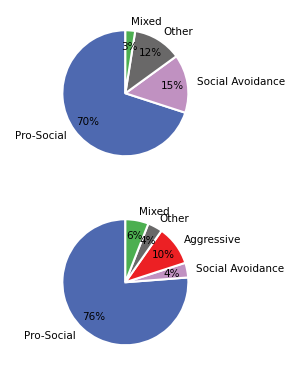

In [19]:
fig, (ax1, ax2) = plt.subplots(2,1, figsize=(1.8,3),dpi=150)
for ax, props, title in [(ax1, props_non_agg_pos, "Non-aggressive mice"),
                         (ax2, props_agg_pos,     "Aggressive mice"),]:
    colors = [color_map.get(b) for b in props.index]
    ax.pie(props.values,
    labels=props.index,
    colors=colors,
    autopct='%1.0f%%',
    pctdistance=0.75,      # pull % labels inward, toward center
    labeldistance=1.15,    # push category labels further out
    textprops=dict(fontsize=5),
    startangle=90,
    wedgeprops=dict(linewidth=1, edgecolor='white'))
    #ax.set_title(title, fontsize=7)
plt.savefig('/Users/amonast/Desktop/miniscope/figures/tuning_pie_chart_positive_only_R2.svg',transparent=True)